# Part A — Non-Local Means (NLM) filtering preprocessing pipeline

A classical denoising preprocessing pipeline for cervical colposcopy images.

## What is "Non-Local Means" here

Non-Local Means (Buades, Coll & Morel, 2005) is an edge-preserving denoising
operator. Each pixel is replaced by a weighted average of ALL pixels inside a
search window; the weight of a candidate pixel comes from the similarity of
its surrounding PATCH to the patch around the pixel being filtered,
`w(i, j) = exp(-||P(i) - P(j)||^2 / h^2)`. "Non-local" means the average is
taken over the whole search window rather than a small neighbourhood, so
repeated structures (vessel texture, epithelial grain) reinforce each other
while structurally unique pixels (edges, boundaries) keep their local
identity — flat noise is averaged away, edges are not blurred the way a
Gaussian or box filter blurs them.

This notebook uses `cv2.fastNlMeansDenoisingColored`: the image is internally
converted to CIELAB, the LUMA channel is denoised with strength `h` and the
CHROMA channels with `hColor`, and the result is converted back to RGB. The
filter acts uniformly on the whole frame — no saliency mask, no bit
allocation, no quantisation, no chroma subsampling.

## Pipeline overview

* Step 0 — Load, BGR -> RGB, resize to 200x200.
* Step 1 — Unsharp-mask sharpen (carried over from Step 1; shared suite
  setting, kept identical so the inputs match the other notebooks).
* Step 2 — Non-Local Means coloured denoising — THE TECHNIQUE UNDER
  EVALUATION (h=3 luma, hColor=3 chroma, patch 7x7, search 21x21).

## Output

The pipeline returns a uint8 RGB image, same shape as the input. It is a
SMOOTHING operator, not a compression scheme: no entropy coding, no byte
stream — the output PNG is approximately the same size as the input PNG. The
pipeline is therefore evaluated as an image-processing technique (fidelity,
structure preservation, diagnostics), not as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.

## Validation scope (Part B)

Exactly ELEVEN metrics are computed per image, inside the FOV, against the
Step-1 original: PSNR (dB), SSIM, ΔE76, a* correlation, |a*| shift,
Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio, Saturation ratio and
Luma bits. Definitions are given in Part B. Tables only.

In [1]:
# ============================================================
# Cell A1 — Combined imports & global setup
# ============================================================
import os, glob, time, json, math, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

# Optional scikit-image backends (the suite validator uses skimage for SSIM /
# CIE76 dE / rgb2lab / Frangi; cv2-only fallbacks keep the notebook runnable
# without it).
try:
    from skimage.metrics import structural_similarity as _sk_ssim
    _SK_SSIM_OK = True
except ImportError:
    _SK_SSIM_OK = False
    print("[warn] scikit-image SSIM not available -- using cv2 fallback.")
try:
    from skimage.color import deltaE_cie76 as _sk_deltaE, rgb2lab as _sk_rgb2lab
    _SK_COLOR_OK = True
except ImportError:
    _SK_COLOR_OK = False
    print("[warn] scikit-image colour not available -- using cv2 fallback.")
try:
    from skimage.filters import frangi as _sk_frangi
    _SK_FRANGI_OK = True
except ImportError:
    _SK_FRANGI_OK = False
    print("[warn] scikit-image Frangi not available -- Sobel ridge fallback.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / JSON artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nNLM Preprocessing + Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"skimage backends: SSIM={_SK_SSIM_OK} colour={_SK_COLOR_OK} frangi={_SK_FRANGI_OK}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


NLM Preprocessing + Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
skimage backends: SSIM=True colour=True frangi=True
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell A2 — Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1) ----
# This setting comes from Step 1 and is shared across the notebook suite.
# It is NOT part of the technique under evaluation; it is kept identical so
# this notebook's inputs (and its numbers) stay comparable with the suite.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Non-Local Means filtering (Step 2, the technique under evaluation) ----
# cv2.fastNlMeansDenoisingColored parameters:
#   NLM_H        -- filter strength for the LUMA channel. Larger = more
#                   smoothing (typical 3-10; small values keep fine detail).
#   NLM_H_COLOR  -- filter strength for the CHROMA channels.
#   NLM_TEMPLATE -- patch size used to compute patch similarity (odd).
#   NLM_SEARCH   -- window in which similar patches are searched (odd).
# These are the same NLM values the suite has used previously; they are now
# applied to the WHOLE image as the standalone preprocessing step.
NLM_H          = 3
NLM_H_COLOR    = 3
NLM_TEMPLATE   = 7
NLM_SEARCH     = 21

# Global flag set by the loader -- declared here so downstream cells can
# reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation scope (Part B) ----
# Part B validates the technique on EVERY loaded image (the 128-frame
# single-patient dataset in the normal case). SUBSET_PER_CLASS can cap it.
SUBSET_PER_CLASS = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen = {APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})  [Step 1, shared]")
print(f"  Step 2 = Non-Local Means coloured filtering: h={NLM_H}, hColor={NLM_H_COLOR}, "
      f"template={NLM_TEMPLATE}, search={NLM_SEARCH}")
print(f"  validation scope = every loaded image (SUBSET_PER_CLASS={SUBSET_PER_CLASS})")

Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen = True (amount=0.8, ksize=5)  [Step 1, shared]
  Step 2 = Non-Local Means coloured filtering: h=3, hColor=3, template=7, search=21
  validation scope = every loaded image (SUBSET_PER_CLASS=None)


In [3]:
# ============================================================
# Cell A3 — Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB image AND its lesion mask (fallback
    used only when the dataset folder is not found, so the notebook can be
    smoke-tested end to end on any machine)."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


NLM filtering done: 128 images in 65.7 s (513.1 ms/image)
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_nlm = (128, 200, 200, 3) uint8 | image_ids = 128 (unique) | SYNTHETIC_MODE = False


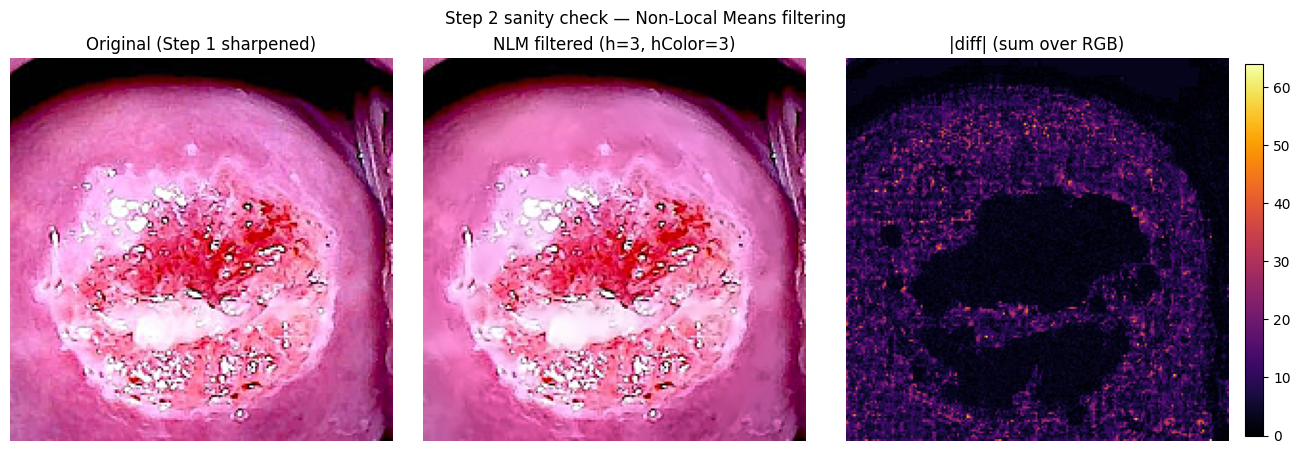

Mean |diff| per pixel (RGB sum): 6.774
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
FOV source ready | X_fov (resize-only) = (128, 200, 200, 3) uint8


In [4]:
# ============================================================
# Cell A4 — Step 2 NLM filtering + bridge to the validator (Part B)
# ============================================================

def nlm_filter(img_rgb, h=None, h_color=None, template=None, search=None):
    """Non-Local Means denoising for colour images (Step 2).

    Wraps cv2.fastNlMeansDenoisingColored: the RGB image is internally
    converted to CIELAB, the luma channel is denoised with strength `h` and
    the chroma channels with `hColor`, then converted back to RGB. Patch
    similarity weights are exp(-||P(i) - P(j)||^2 / h^2) over all patches in
    the search window, so flat noisy regions are strongly averaged while
    structurally unique edges keep their identity.
    """
    h        = NLM_H        if h        is None else h
    h_color  = NLM_H_COLOR  if h_color  is None else h_color
    template = NLM_TEMPLATE if template is None else template
    search   = NLM_SEARCH   if search   is None else search
    return cv2.fastNlMeansDenoisingColored(img_rgb, None, h, h_color,
                                           template, search)

# ---- Bridge: names expected by the Part B validator ----------------------
# X_base : Step-1 output (resize + sharpen) = the validator's "original"
# X_nlm  : Step-2 NLM output                = the technique under test
# X_fov  : resize-only reload               = FOV-mask source (Part B)
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))], dtype=object)
assert len(set(image_ids)) == len(X_base), "image_ids not unique (should never happen)"

# --- Apply the technique to every image (timed) ---
_t0 = time.time()
X_nlm = np.stack([nlm_filter(img) for img in X_base]).astype(np.uint8)
_nlm_total_s = time.time() - _t0
print(f"NLM filtering done: {len(X_base)} images in {_nlm_total_s:.1f} s "
      f"({_nlm_total_s / max(len(X_base), 1) * 1000:.1f} ms/image)")

# --- Determinism smoke test (same input -> same output) -------------------
assert np.array_equal(nlm_filter(X_base[0]), X_nlm[0]), "NLM is not deterministic"
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_nlm = {X_nlm.shape} {X_nlm.dtype} | image_ids = {len(image_ids)} (unique) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# --- Visual sanity check: original | NLM | amplified difference -----------
_diff = np.abs(X_nlm[0].astype(np.int16) - X_base[0].astype(np.int16)).sum(axis=2)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
axes[0].imshow(X_base[0]); axes[0].set_title("Original (Step 1 sharpened)"); axes[0].axis('off')
axes[1].imshow(X_nlm[0]);   axes[1].set_title(f"NLM filtered (h={NLM_H}, hColor={NLM_H_COLOR})"); axes[1].axis('off')
im = axes[2].imshow(_diff, cmap='inferno'); axes[2].set_title("|diff| (sum over RGB)"); axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle("Step 2 sanity check — Non-Local Means filtering")
plt.show()
print(f"Mean |diff| per pixel (RGB sum): {_diff.mean():.3f}")

# --- Reload the SAME images WITHOUT sharpening -> FOV source --------------
#     (used only as the source for the field-of-view mask in Part B)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES, size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS, sharpen_it=False,
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_fov = X_base.copy()
    else:
        X_fov = _X_unsharp
        if len(X_fov) != len(X_base):
            print(f"[bridge] X_fov count ({len(X_fov)}) != X_base count ({len(X_base)}); "
                  f"falling back to X_base.")
            X_fov = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the sharpen
    # pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_fov = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_fov[i] = np.clip(X_fov[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)

assert X_fov.shape == X_base.shape, f"X_fov {X_fov.shape} != X_base {X_base.shape}"
print(f"FOV source ready | X_fov (resize-only) = {X_fov.shape} {X_fov.dtype}")

# Part B — Validation: 11 metrics, tables only

Single-patient dataset. Frames are grouped into dHash clusters; the frames
are NOT independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Non-Local Means coloured filtering (Step 2).

**Metrics:** ELEVEN metrics in 4 groups (fidelity, colour, structure,
quality) + one cost/diagnostic metric. All computed inside the FOV mask
only, per image, against the Step-1 ORIGINAL (X_base). No other metric is
reported anywhere in this notebook.

| # | Metric | Group | Definition | Better |
|---|--------|-------|------------|--------|
| m1 | PSNR (dB) | fidelity | 10·log10(255² / MSE), inside the FOV | up |
| m2 | SSIM | fidelity | skimage SSIM (channel_axis=2, data_range=255), per-channel map averaged, inside the FOV | up |
| m3 | ΔE76 | colour | mean CIE 1976 L\*a\*b\* colour difference (skimage deltaE_cie76), inside the FOV | down |
| m4 | a\* correlation | colour | Pearson r of the CIELAB a\* channel, inside the FOV | up |
| m5 | \|a\*\| shift | colour | \|mean a\*(proc) − mean a\*(orig)\|, inside the FOV | down |
| m6 | Vessel Dice | structure | Dice of the top-10% Frangi vessel pixels, inside the FOV | up |
| m7 | Edge IoU | structure | IoU of Canny(50, 150) edge maps, inside the FOV | up |
| m8 | Sharpness ratio | quality | Laplacian variance (proc / orig), inside the FOV | neutral |
| m9 | Noise ratio | quality | robust high-pass noise σ (1.4826·MAD in smooth regions), proc / orig | down |
| m10 | Saturation ratio | quality | saturated-specular pixel count (HSV V≥250 & S≤25), proc / orig; >1 means NEW saturated pixels were introduced | ≤1 |
| m11 | Luma bits | cost | effective luma bit usage: Shannon entropy of the 256-bin luma histogram of the OUTPUT (bits/px, 0–8) | neutral |

Notes.

* The suite's quantising techniques report the ALLOCATED luma bits (their
  bit budget). NLM does not quantise — the output is a full 8-bit image —
  so m11 here reports the EFFECTIVE luma bit usage (histogram entropy) of
  the output instead.
* The Frangi vessel map is a proxy computed from the images themselves; no
  clinician annotation is required or implied.
* scikit-image backends are used when available (SSIM, CIE76 dE, rgb2lab,
  Frangi); cv2-only fallbacks keep the notebook runnable without it.

**Tables only.** No figures, no plots. T1 (main), plus per-image CSV and
JSON artefacts for the multi-technique merge.

In [5]:
# ============================================================
# Cell B1 — Freeze inputs: FOV masks, dHash cluster ids
# ============================================================

def _dhash(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov(img_rgb, thr=15):
    """FOV mask (largest bright component, hole-filled + convex-hull closed).
    Same as the suite validator's FOV computation."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (same as the suite validator)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                     cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

n_images = len(X_base)
fov = np.stack([_compute_fov(X_fov[i]) for i in range(n_images)])
print(f"FOV masks: {n_images} | mean FOV coverage = {fov.mean():.3f}")

# dHash clustering (same as the suite validator): frames within Hamming
# distance 4 share a cluster. Used ONLY for the cluster-weighted summary --
# the frames are NOT independent.
hs = [_dhash(cv2.cvtColor(X_base[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
print(f"n_images = {n_images} | n_clusters (dHash) = {n_clusters}")
print(f"The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). The T1 table says this.")

FOV masks: 128 | mean FOV coverage = 0.958
n_images = 128 | n_clusters (dHash) = 7
The 128 frames are NOT independent (7 distinct clusters from one patient). The T1 table says this.


In [6]:
# ============================================================
# Cell B2 — Validator: exactly the 11 reported metrics
#   m1..m10 are identical to the suite validator (step4_validator).
#   m11 (Luma bits) is the NLM analogue of the suite's bit metric.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    if _SK_FRANGI_OK:
        v = _sk_frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    else:
        # Fallback: Sobel-based ridge detection (suite fallback)
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside the
    FOV, then computes Dice = 2*|A∩B| / (|A|+|B|)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map (fixed 50/150 thresholds, suite-standard)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _rgb2lab(img_rgb):
    """RGB -> CIELAB. skimage rgb2lab when available (suite-standard),
    otherwise a cv2 fallback on the same L in [0,100] / a,b in [-127,127]
    scale."""
    if _SK_COLOR_OK:
        return _sk_rgb2lab(img_rgb)
    lab8 = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float64)
    out = np.empty_like(lab8)
    out[..., 0] = lab8[..., 0] * (100.0 / 255.0)
    out[..., 1] = lab8[..., 1] - 128.0
    out[..., 2] = lab8[..., 2] - 128.0
    return out

def _deltaE76(lab_o, lab_p):
    """CIE 1976 colour difference map (Euclidean distance in Lab)."""
    if _SK_COLOR_OK:
        return _sk_deltaE(lab_o, lab_p)
    return np.sqrt(((lab_o - lab_p) ** 2).sum(axis=-1))

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Saturated-specular mask (suite validator definition: HSV V>=250 & S<=25)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _ssim_map(original, processed):
    """Per-channel SSIM map, averaged over channels (data_range=255).
    skimage backend when available; otherwise a Gaussian-window SSIM per
    channel (11x11, sigma=1.5, C1/C2 standard)."""
    if _SK_SSIM_OK:
        return _sk_ssim(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    g_o = original.astype(np.float64); g_p = processed.astype(np.float64)
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    acc = np.zeros(original.shape[:2], dtype=np.float64)
    for c in range(3):
        a, b = g_o[..., c], g_p[..., c]
        mu_a = cv2.GaussianBlur(a, (11, 11), 1.5)
        mu_b = cv2.GaussianBlur(b, (11, 11), 1.5)
        s_a2 = cv2.GaussianBlur(a * a, (11, 11), 1.5) - mu_a * mu_a
        s_b2 = cv2.GaussianBlur(b * b, (11, 11), 1.5) - mu_b * mu_b
        s_ab = cv2.GaussianBlur(a * b, (11, 11), 1.5) - mu_a * mu_b
        num = (2 * mu_a * mu_b + C1) * (2 * s_ab + C2)
        den = (mu_a * mu_a + mu_b * mu_b + C1) * (s_a2 + s_b2 + C2)
        acc += num / den
    return acc / 3.0

def luma_bits(img_rgb):
    """Effective luma bit usage (m11).

    NLM does not quantise: the output is a full 8-bit image, so instead of
    the suite's ALLOCATED-bits metric this reports the EFFECTIVE luma bit
    usage: Shannon entropy of the 256-bin histogram of the luma channel,
    in bits/px (0..8). 8.0 = all 256 levels used evenly."""
    y = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)[..., 0]
    hist = np.bincount(y.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def nlm_validator(original, processed, fov_mask):
    """Compute the 11 reported metrics inside the FOV only, per image.

      m1  PSNR (dB)           up
      m2  SSIM                up
      m3  ΔE76                down
      m4  a* correlation      up
      m5  |a*| shift          down
      m6  Vessel Dice         up
      m7  Edge IoU            up
      m8  Sharpness ratio     neutral (0.9-1.1) / higher
      m9  Noise ratio         down
      m10 Saturation ratio    at most 1
      m11 Luma bits (output)  neutral (diagnostic)
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked, per-channel map averaged)
    m2 = float(_ssim_map(original, processed).mean(2)[f].mean())
    # m3: ΔE76 (CIE76, FOV-masked)
    lab_o = _rgb2lab(original)
    lab_p = _rgb2lab(processed)
    m3 = float(_deltaE76(lab_o, lab_p)[f].mean())
    # m4: a* correlation
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |a*| shift
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    m7 = _edge_iou(_edge_map(original), _edge_map(processed), f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of the high-pass in smooth regions
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (saturated-specular pixel count, out/in).
    # Measures NEW saturation introduced by the technique, NOT glare removal.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (effective bit usage of the OUTPUT)
    m11 = luma_bits(processed)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (key, name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",         "fidelity",  "up"),
    ("m2",  "SSIM",              "fidelity",  "up"),
    ("m3",  "ΔE76",              "colour",    "down"),
    ("m4",  "a* correlation",    "colour",    "up"),
    ("m5",  "|a*| shift",        "colour",    "down"),
    ("m6",  "Vessel Dice",       "structure", "up"),
    ("m7",  "Edge IoU",          "structure", "up"),
    ("m8",  "Sharpness ratio",   "quality",   "neutral"),
    ("m9",  "Noise ratio",       "quality",   "down"),
    ("m10", "Saturation ratio",  "quality",   "neutral"),
    ("m11", "Luma bits",         "cost",      "neutral"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print(f"Validator ready: {len(METRIC_KEYS)} metrics (m1..m11):")
for _k in METRIC_KEYS:
    print(f"  {_k:<4} {METRIC_NAMES[_k]:<17} [{METRIC_GROUPS[_k]:<9}] better: {METRIC_BETTER[_k]}")

Validator ready: 11 metrics (m1..m11):
  m1   PSNR (dB)         [fidelity ] better: up
  m2   SSIM              [fidelity ] better: up
  m3   ΔE76              [colour   ] better: down
  m4   a* correlation    [colour   ] better: up
  m5   |a*| shift        [colour   ] better: down
  m6   Vessel Dice       [structure] better: up
  m7   Edge IoU          [structure] better: up
  m8   Sharpness ratio   [quality  ] better: neutral
  m9   Noise ratio       [quality  ] better: down
  m10  Saturation ratio  [quality  ] better: neutral
  m11  Luma bits         [cost     ] better: neutral


In [7]:
# ============================================================
# Cell B3 — Run the validator: NLM (the technique) + Identity (reference)
#   Writes results_NLM.csv and results_Identity.csv (suite naming).
# ============================================================

# Remove stale outputs of THIS notebook only (do not touch other
# notebooks' results_* files).
for _old in ("results_NLM.csv", "results_Identity.csv"):
    if os.path.isfile(_old):
        os.remove(_old)
        print(f"  Deleted stale {_old}")

TECHNIQUE = "NLM"

def nlm_technique(img, params=None):
    """NLM filtering, exposed to the validator (suite API: img -> uint8 RGB).
    `params` is accepted for API compatibility but ignored (fixed module-level
    configuration; no tuning on a single patient)."""
    return nlm_filter(img)

def _validate_technique(technique_name, technique_fn):
    """Validate a technique(image) -> image function on every loaded image."""
    rows = []
    for i in range(n_images):
        orig = X_base[i]
        t0 = time.perf_counter()
        proc = technique_fn(orig)
        elapsed_ms = (time.perf_counter() - t0) * 1000
        m = nlm_validator(orig, proc, fov[i])
        m["technique"] = technique_name
        m["image_id"] = image_ids[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        if (i + 1) % 20 == 0 or i == n_images - 1:
            print(f"  {technique_name}: processed {i + 1}/{n_images} images "
                  f"(technique call: {elapsed_ms:.0f} ms/image)")
    return pd.DataFrame(rows)

df_nlm = _validate_technique(TECHNIQUE, nlm_technique)
df_nlm.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_nlm)} rows)")

# Identity reference row (ideal values; sanity check for the metric code).
df_id = _validate_technique("Identity", lambda img: img.copy())
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

merged = pd.concat([df_nlm, df_id], ignore_index=True)

# Hard sanity: no NaN in any metric column.
_nan_cols = {c: int(merged[c].isna().sum()) for c in METRIC_KEYS
             if merged[c].isna().sum() > 0}
assert len(_nan_cols) == 0, f"NaN values found: {_nan_cols}"
print("No NaN values in any metric column.")

# Identity must score ideally on every metric.
_id_row = df_id[METRIC_KEYS].mean()
print("\nIdentity reference (should be ideal):  "
      f"SSIM={_id_row['m2']:.4f}  dE76={_id_row['m3']:.4f}  "
      f"a*corr={_id_row['m4']:.4f}  |a*shift|={_id_row['m5']:.4f}  "
      f"VesselDice={_id_row['m6']:.4f}  EdgeIoU={_id_row['m7']:.4f}  "
      f"Sharp={_id_row['m8']:.4f}  Noise={_id_row['m9']:.4f}")

  Deleted stale results_Identity.csv
  NLM: processed 20/128 images (technique call: 474 ms/image)
  NLM: processed 40/128 images (technique call: 501 ms/image)
  NLM: processed 60/128 images (technique call: 398 ms/image)
  NLM: processed 80/128 images (technique call: 461 ms/image)
  NLM: processed 100/128 images (technique call: 435 ms/image)
  NLM: processed 120/128 images (technique call: 470 ms/image)
  NLM: processed 128/128 images (technique call: 440 ms/image)
Wrote results_NLM.csv (128 rows)
  Identity: processed 20/128 images (technique call: 0 ms/image)
  Identity: processed 40/128 images (technique call: 0 ms/image)
  Identity: processed 60/128 images (technique call: 0 ms/image)
  Identity: processed 80/128 images (technique call: 0 ms/image)
  Identity: processed 100/128 images (technique call: 0 ms/image)
  Identity: processed 120/128 images (technique call: 0 ms/image)
  Identity: processed 128/128 images (technique call: 0 ms/image)
Wrote results_Identity.csv (128 row

In [8]:
# ============================================================
# Cell B4 — Aggregation: average within each cluster first, then across
#   clusters. 95% CI from a cluster bootstrap (2000 resamples, seed 42).
#   Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples, seed 42).
    Returns (mean, ci_lo, ci_hi). WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

techniques = sorted(merged["technique"].unique())
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")

# ---- T1 MAIN table -------------------------------------------------------
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

print("=" * 118)
print("T1 MAIN  (cluster-weighted mean [95% CI]; "
      f"WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent "
      f"({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 118)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- Save summary artefacts ----------------------------------------------
agg_df.to_csv(os.path.join(SAVE_DIR, "nlm_validation_T1_summary.csv"))
with open(os.path.join(SAVE_DIR, "nlm_validation_summary.json"), "w",
          encoding="utf-8") as f:
    json.dump({
        "technique": "Non-Local Means (colored) filtering",
        "params": {"h": NLM_H, "hColor": NLM_H_COLOR,
                   "templateWindowSize": NLM_TEMPLATE,
                   "searchWindowSize": NLM_SEARCH},
        "sharpen": {"applied": APPLY_SHARPEN, "amount": SHARPEN_AMOUNT,
                    "ksize": SHARPEN_KSIZE},
        "n_images": int(n_images),
        "n_clusters_dhash": int(n_clusters),
        "synthetic_mode": bool(SYNTHETIC_MODE),
        "metrics": [METRIC_NAMES[k] for k in METRIC_KEYS],
        "T1_cluster_weighted_mean_ci": {
            tech: {METRIC_NAMES[mk]: {
                        "mean": float(agg_df.loc[tech, mk]),
                        "ci95": [float(agg_df.loc[tech, f"{mk}_lo"]),
                                 float(agg_df.loc[tech, f"{mk}_hi"])]}
                   for mk in METRIC_KEYS}
            for tech in techniques},
    }, f, indent=2, ensure_ascii=False)
print(f"\nSaved artefacts -> {SAVE_DIR}/nlm_validation_T1_summary.csv"
      f" | {SAVE_DIR}/nlm_validation_summary.json")

T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                        PSNR (dB) (^)              SSIM (^)              ΔE76 (v)    a* correlation (^)        |a*| shift (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (o)
technique                                                                                                                                                                                                                                                        
Identity   148.131 [148.131, 148.131]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  7.598 [7.548, 7.663]


## How to read the T1 row for NLM

Expected signature of Non-Local Means at h=3 / hColor=3 on 200x200 frames:

* **Noise ratio (m9) clearly below 1** — the primary effect: high-pass noise
  sigma drops in smooth regions while structure is retained.
* **PSNR / SSIM high, ΔE76 small** — the filter changes the image only where
  patches are repetitive (noise-like), so global fidelity stays high.
* **a\* correlation near 1, \|a\*\| shift near 0** — the spatial pattern and
  the mean level of the red-green opponent channel are preserved (chroma is
  only touched by hColor=3).
* **Vessel Dice / Edge IoU high** — dark vessel structures and edge
  locations stay where they were.
* **Sharpness ratio slightly below 1** — mild smoothing of fine texture.
* **Saturation ratio ≤ 1** — NLM should not create new saturated-specular
  pixels; a value above 1 would mean it does.
* **Luma bits (m11)** — the output stays a full 8-bit image; the metric
  tracks how much of the luma range the smoothed image actually uses.

Caveats (unchanged from the suite):

* Descriptive only — no p-values, no robustness or population claims.
* The frames are NOT independent (dHash clusters from one patient); the CI
  is a within-patient cluster bootstrap, NOT a population CI.
* Identity is a reference row for the metric code, not a technique.

Artefacts written by this notebook:

* `results_NLM.csv` — per-image metrics (technique, image_id, cluster_id, m1..m11).
* `results_Identity.csv` — identity reference rows (validator sanity check).
* `results/nlm_validation_T1_summary.csv` — cluster-weighted mean + 95% CI per metric.
* `results/nlm_validation_summary.json` — run provenance + T1 as JSON.